# 01 · Cosine, Q and dimension

For a single unit vector, $Q(u)=uu^T-I_d/d$. Direct expansion gives $\langle Q(u),Q(v)\rangle=(u^Tv)^2-1/d$ and $\|Q(u)\|^2=1-1/d$. Thus its normalized similarity equals $H_2(t)=(dt^2-1)/(d-1)$. This equals Legendre $P_2$ in three dimensions.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

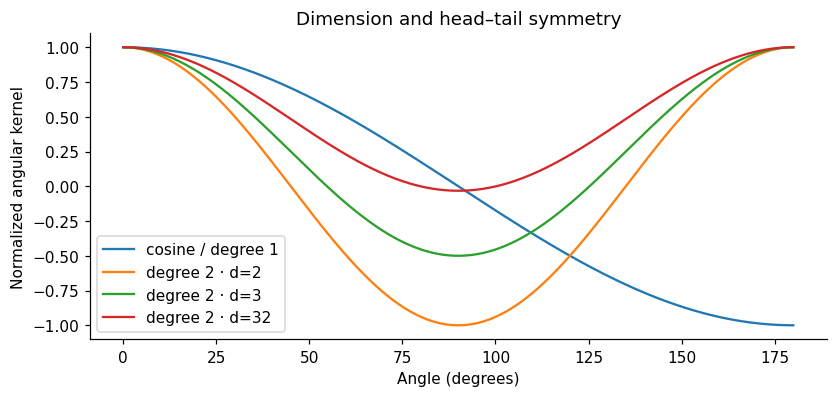

In [3]:
theta=np.linspace(0,np.pi,361);t=np.cos(theta)
fig,ax=plt.subplots()
ax.plot(np.degrees(theta),t,label='cosine / degree 1')
for dimension in (2,3,32):
    ax.plot(np.degrees(theta),spherical_kernel(t,2,dimension),label=f'degree 2 · d={dimension}')
ax.set(xlabel='Angle (degrees)',ylabel='Normalized angular kernel',title='Dimension and head–tail symmetry')
ax.legend();show('01_angular_kernels')

## Tensor contraction checked independently
For distributions of directions, $\langle M_A^{(k)},M_B^{(k)}\rangle=\mathbb E_{A,B}[(u^Tv)^k]$. Raw tensor powers contain lower harmonic components. Harmonic degree $\ell$ isolates angular order. On the circle it uses $\cos(\ell\theta)$; in $d>2$ it uses normalized Gegenbauer $C_\ell^{(d-2)/2}(t)$.

In [5]:
rng=np.random.default_rng(SEED)
u=rng.normal(size=(10,5));u/=np.linalg.norm(u,axis=1)[:,None]
v=rng.normal(size=(12,5));v/=np.linalg.norm(v,axis=1)[:,None]
rows=[]
for k in (1,2,3,4):
    tensor=np.sum(tensor_moment(u,k)*tensor_moment(v,k))
    kernel=np.mean((u@v.T)**k)
    rows.append((k,tensor,kernel,abs(tensor-kernel)))
display(pd.DataFrame(rows,columns=['order','tensor contraction','pair kernel average','absolute error']))
assert max(row[-1] for row in rows)<1e-12
m,q=moments(u);n,r=moments(v)
assert np.isclose(angular_kernel_mean(u,v,2),5*np.sum(q*r)/4)

,order,tensor contraction,pair kernel average,absolute error
0,1,-0.073516,-0.073516,1.387779e-17
1,2,0.189191,0.189191,5.551115e-17
2,3,-0.015569,-0.015569,1.561251e-17
3,4,0.077605,0.077605,1.387779e-17


## A single-vector transformation can preserve every ranking
For t ≥ 0, H₂(t) is strictly increasing in t. For signed t it ranks |t|. Head–tail equivalence has to match the task. Shared orthogonal changes of feature coordinates preserve all these contractions. Independent rotations of the two feature spaces generally change them.

In [7]:
positive_cosines=np.array([.1,.4,.6,.8,.95])
assert np.array_equal(np.argsort(positive_cosines),np.argsort(spherical_kernel(positive_cosines,2,128)))
display(pd.DataFrame({'cosine':positive_cosines,'H2 in 128D':spherical_kernel(positive_cosines,2,128)}))
print('Identical rankings for all five nonnegative cosine values.')

,cosine,H2 in 128D
0,0.10,0.002205
1,0.40,0.153386
2,0.60,0.354961
3,0.80,0.637165
4,0.95,0.901732


Identical rankings for all five nonnegative cosine values.


## Check before extending
Legendre polynomials are usable scalar functions in any dimension. The orthogonal angular decomposition appropriate to the uniform sphere changes with dimension. Unit directions encode orientation; retain feature norms separately if amplitudes matter.